# Image Tiling

Loads the tiled dataset from `scripts/dataset.py` and checks that it looks right.

- `X`: (N, 256, 256, 4) float32. Channels are R, G, B (0-1) and the DEM minus the image mean.
- `y`: (N, 256, 256) int8. 0 = dry, 1 = flood, -1 = unknown.

The split is by whole image, so no tile from a test image ends up in training.

In [7]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("../scripts")
from dataset import load_dataset

## Load the dataset

Training tiles overlap by half and skip tiles that are mostly unknown. Val and test keep every tile.

In [8]:
data = load_dataset()
X_train, y_train = data["train"]
X_val, y_val = data["val"]
X_test, y_test = data["test"]

for name, (X, y) in data.items():
    known = y[y != -1]
    print(f"{name:5}  {len(X):5} tiles  {X.nbytes / 1e9:.2f} GB  flood {known.mean():.1%}  unknown {(y == -1).mean():.1%}")

train   1571 tiles  1.65 GB  flood 55.8%  unknown 9.4%
val      110 tiles  0.12 GB  flood 51.3%  unknown 20.0%
test     287 tiles  0.30 GB  flood 76.0%  unknown 48.5%


## Look at some tiles

Val and test keep every tile, including ones that are almost all unknown, so only tiles at most 50% unknown are shown here.

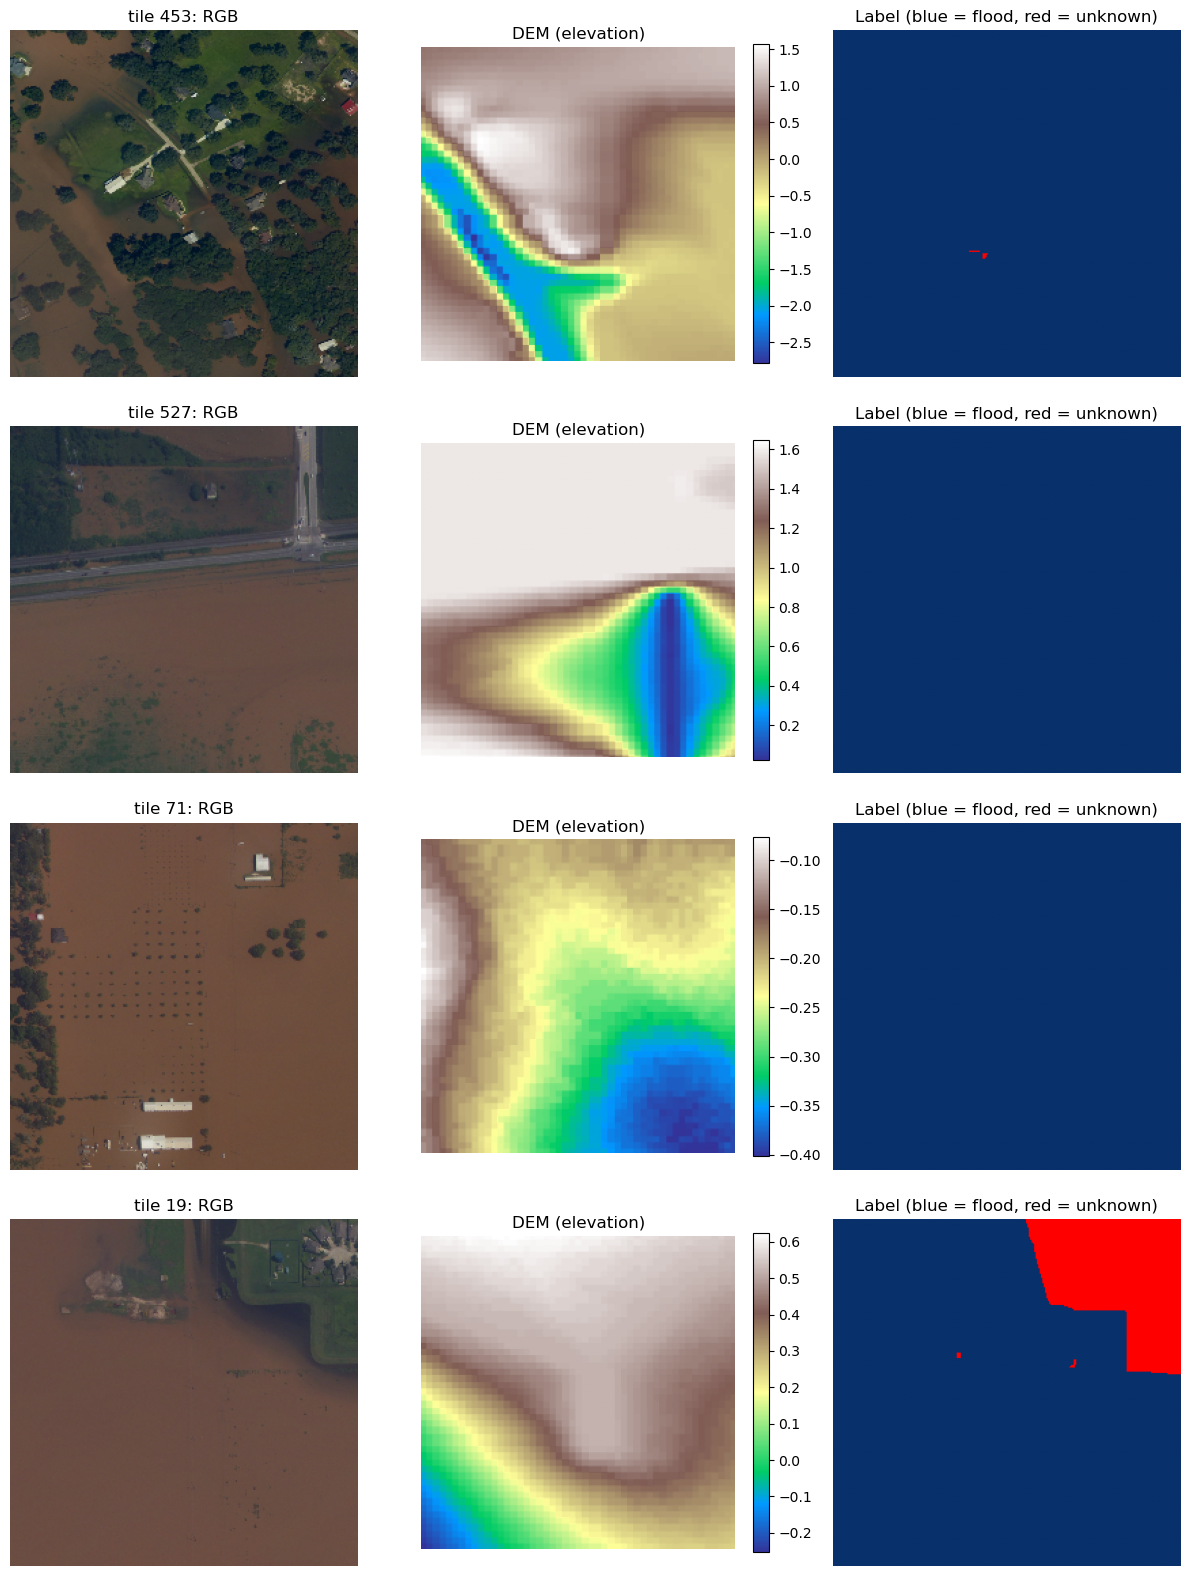

In [11]:
def show_tiles(X, y, n=4, seed=None):
    unknown = (y == -1).mean(axis=(1, 2))  # share of unknown pixels per tile
    mostly_known = np.where(unknown <= 0.5)[0]
    picks = np.random.default_rng(seed).choice(mostly_known, n, replace=False)  # seed=None -> new tiles each run

    cmap = plt.get_cmap("Blues").copy()
    cmap.set_bad("red")  # unknown (-1) pixels

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n), squeeze=False)
    for row, k in enumerate(picks):
        axes[row, 0].imshow(X[k, :, :, :3])
        axes[row, 0].set_title(f"tile {k}: RGB")

        im = axes[row, 1].imshow(X[k, :, :, 3], cmap="terrain")
        axes[row, 1].set_title("DEM (elevation)")
        fig.colorbar(im, ax=axes[row, 1], fraction=0.046)

        axes[row, 2].imshow(np.ma.masked_equal(y[k], -1), cmap=cmap, vmin=0, vmax=1)
        axes[row, 2].set_title("Label (blue = flood, red = unknown)")
    for ax in axes.flat:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_tiles(X_train, y_train)